# Suport amb eix fix: concentració de tensions

**Disseny i assaig de màquines (DiAM)** · J.A. Mayugo, UdG

Estat de tensions del punt **a** de la secció **A** d'un eix fix amb politja i corretja, tenint en compte la concentració de tensions a l'acord de radi R4.

## Llibreries

In [1]:
# Autor: J.A. Mayugo, 2019-2026 (versió Python de DiAM_eixfix_SOL.m)

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import RegularGridInterpolator

plt.rcParams['svg.fonttype'] = 'none'

## Funcions: factors de concentració i sensibilitat a l'entalla

$K_t$ i $K_{ts}$ per fórmula i per gràfic (interpolació bilineal), i sensibilitat a l'entalla $q$.

In [2]:
def K_t_rodo_flexio(D_d, r_d):
    """K_t d'un rodó sotmès a flexió amb un canvi de secció de D a d.
    D_d = D/d ; r_d = r/d (fórmula de Peterson)."""
    return (0.632 + 0.377*D_d**(-4.4)
            + r_d**(-0.5)*np.sqrt((-0.14 - 0.363*D_d**2 + 0.503*D_d**4)
                                  /(1 - 2.39*D_d**2 + 3.368*D_d**4)))

def K_t_rodo_torsio(D_d, r_d):
    """K_ts d'un rodó sotmès a torsió amb un canvi de secció de D a d."""
    return (0.78 + 0.2*D_d**(-10)
            + r_d**(-0.46)*np.sqrt((0.002 - 0.125*D_d**2 + 0.123*D_d**4)
                                   /(1 - 2.75*D_d**2 + 2.55*D_d**4)))

# Dades dels gràfics: relació r/d en columnes i D/d en files
r_d_vec = np.array([0.025, 0.050, 0.075, 0.100, 0.125, 0.150, 0.175, 0.200, 0.225, 0.250, 0.275, 0.300])
D_d_vec_f = np.array([1.02, 1.05, 1.1, 1.5, 3])
data_f = np.array([
    [1.913, 1.667, 1.537, 1.450, 1.388, 1.341, 1.304, 1.268, 1.239, 1.228, 1.209, 1.198],
    [2.140, 1.804, 1.645, 1.544, 1.471, 1.410, 1.359, 1.326, 1.297, 1.275, 1.257, 1.238],
    [2.256, 1.884, 1.699, 1.594, 1.515, 1.464, 1.413, 1.366, 1.366, 1.366, 1.366, 1.366],
    [2.591, 2.075, 1.826, 1.677, 1.572, 1.507, 1.460, 1.416, 1.400, 1.400, 1.400, 1.400],
    [2.852, 2.317, 2.002, 1.803, 1.677, 1.587, 1.510, 1.452, 1.402, 1.362, 1.325, 1.307]])
D_d_vec_t = np.array([1.09, 1.20, 1.33, 2])
data_t = np.array([
    [1.489, 1.290, 1.209, 1.165, 1.140, 1.125, 1.114, 1.106, 1.100, 1.100, 1.100, 1.100],
    [1.915, 1.592, 1.434, 1.345, 1.283, 1.239, 1.195, 1.162, 1.140, 1.125, 1.118, 1.105],
    [2.033, 1.695, 1.518, 1.426, 1.353, 1.305, 1.254, 1.224, 1.195, 1.180, 1.173, 1.170],
    [2.154, 1.768, 1.573, 1.467, 1.397, 1.342, 1.301, 1.261, 1.228, 1.202, 1.191, 1.180]])
interp_f = RegularGridInterpolator((D_d_vec_f, r_d_vec), data_f)    # interpolació bilineal
interp_t = RegularGridInterpolator((D_d_vec_t, r_d_vec), data_t)

def K_t_rodo_flexio_grafica(D_d, r_d):
    """K_t a partir de les dades del gràfic (interpolació bilineal)."""
    r_d = np.atleast_1d(np.clip(r_d, 0.025, 0.3))
    D_d = np.clip(D_d, 1.02, 3)
    K = interp_f(np.column_stack([np.full(r_d.shape, D_d), r_d]))
    return K if K.size > 1 else float(K[0])

def K_t_rodo_torsio_grafica(D_d, r_d):
    """K_ts a partir de les dades del gràfic (interpolació bilineal)."""
    r_d = np.atleast_1d(np.clip(r_d, 0.025, 0.3))
    D_d = np.clip(D_d, 1.09, 2)
    K = interp_t(np.column_stack([np.full(r_d.shape, D_d), r_d]))
    return K if K.size > 1 else float(K[0])

def q_sensibilitat_entalla(r, Sut, tallant=False):
    """Sensibilitat a l'entalla q per a acers (r en mm, Sut en MPa).
    Les fórmules treballen en [in] i [kpsi]."""
    Sut_kpsi = Sut/6.9
    r_in = r/25.4
    if not tallant:
        sqr_a = 0.246 - 3.08e-3*Sut_kpsi + 1.51e-5*Sut_kpsi**2 - 2.67e-8*Sut_kpsi**3
    else:
        sqr_a = 0.190 - 2.51e-3*Sut_kpsi + 1.35e-5*Sut_kpsi**2 - 2.67e-8*Sut_kpsi**3
    return 1/(1 + sqr_a/np.sqrt(r_in))

## Dades del problema

In [3]:
l  = 60.0           # mm, distància canvi de secció - politja
R  = 100.0          # mm, radi de la politja
D  = 25.0           # mm, diàmetre gran de l'eix
d  = 20.0           # mm, diàmetre petit de l'eix
r4 = 4.0            # mm, radi d'acord R4
r_ = np.arange(1.0, 5.0 + 1e-9, 0.1)    # mm, radis de l'apartat 5
F1 = 100.0          # N, tensió de la corretja 1
F2 = 400.0          # N, tensió de la corretja 2
v  = 0.6            # m/s, velocitat de la corretja
Sut = 750.0         # MPa, resistència última
Sy  = 550.0         # MPa, límit elàstic

## Apartat 1): sentit de moviment i potència dissipada

$F_f = F_2 - F_1$, $P = F_f\,v$

In [4]:
P_fric = (F2 - F1)*v                                    # W
print(f"Apartat 1): força de fricció = {F2 - F1:.0f} N, potència dissipada = {P_fric:.0f} W")

Apartat 1): força de fricció = 300 N, potència dissipada = 180 W


## Funció que calcula l'estat de tensions

Solicitacions, tensions nominals, factors de concentració i tensió de von Mises per a un radi $r$.

In [5]:
def tensions(r):
    M = (l - r)*(F1 + F2)                               # N·mm
    T = R*(F2 - F1)                                     # N·mm
    sigma_0 = 32*M/(np.pi*d**3)                         # MPa
    tau_0   = 16*T/(np.pi*d**3)                         # MPa
    K_t,  K_ts  = K_t_rodo_flexio(D/d, r/d), K_t_rodo_torsio(D/d, r/d)
    K_tg, K_tsg = K_t_rodo_flexio_grafica(D/d, r/d), K_t_rodo_torsio_grafica(D/d, r/d)
    q,  qs = q_sensibilitat_entalla(r, Sut), q_sensibilitat_entalla(r, Sut, True)
    K_f,  K_fs  = 1 + q*(K_t - 1),  1 + qs*(K_ts - 1)
    K_fg, K_fsg = 1 + q*(K_tg - 1), 1 + qs*(K_tsg - 1)
    VM = lambda Ks, Kt_: np.sqrt((sigma_0*Ks)**2 + 3*(tau_0*Kt_)**2)
    return dict(M=M, T=T, sigma_0=sigma_0, tau_0=tau_0, K_t=K_t, K_ts=K_ts, K_tg=K_tg, K_tsg=K_tsg,
                q=q, qs=qs, K_f=K_f, K_fs=K_fs, K_fg=K_fg, K_fsg=K_fsg,
                VM_a=VM(K_t, K_ts), VM_ag=VM(K_tg, K_tsg), VM_b=VM(K_f, K_fs), VM_bg=VM(K_fg, K_fsg),
                VM_c=VM(1.0, 1.0))

## Apartats 2) a 4): estat de tensions per a $r = $ R4 = 4 mm

In [6]:
S = tensions(r4)
print(f"\nSolicitacions: M = {S['M']:.0f} N·mm, T = {S['T']:.0f} N·mm, V = {F1 + F2:.0f} N")
print(f"Tensions nominals: sigma_0 = {S['sigma_0']:.2f} MPa, tau_0 = {S['tau_0']:.2f} MPa")
print(f"K_t = {S['K_t']:.3f} (fórmula), {S['K_tg']:.3f} (gràfic); "
      f"K_ts = {S['K_ts']:.3f} (fórmula), {S['K_tsg']:.3f} (gràfic)")
print(f"q = {S['q']:.3f}, q_s = {S['qs']:.3f}")
print(f"K_f = {S['K_f']:.3f}, K_fs = {S['K_fs']:.3f} (fórmula); K_f = {S['K_fg']:.3f}, K_fs = {S['K_fsg']:.3f} (gràfic)")

def estat(K1, K2, etiqueta):
    sigma = K1*S['sigma_0']; tau = K2*S['tau_0']
    s1 = sigma/2 + np.sqrt((sigma/2)**2 + tau**2)
    s2 = sigma/2 - np.sqrt((sigma/2)**2 + tau**2)
    vm = np.sqrt(sigma**2 + 3*tau**2)
    print(f"{etiqueta:<22} sigma = {sigma:6.2f}  tau = {tau:6.2f}  sigma_1 = {s1:6.2f}  sigma_2 = {s2:6.2f}  "
          f"sigma_VM = {vm:6.2f}  SF = {Sy/vm:5.2f}")
estat(S['K_t'],  S['K_ts'],  'K_t, K_ts (fórmula)')
estat(S['K_tg'], S['K_tsg'], 'K_t, K_ts (gràfic)')
estat(S['K_f'],  S['K_fs'],  'K_f, K_fs (fórmula)')
estat(S['K_fg'], S['K_fsg'], 'K_f, K_fs (gràfic)')
estat(1.0, 1.0, 'q = 0')


Solicitacions: M = 28000 N·mm, T = 30000 N·mm, V = 500 N
Tensions nominals: sigma_0 = 35.65 MPa, tau_0 = 19.10 MPa
K_t = 1.462 (fórmula), 1.385 (gràfic); K_ts = 1.202 (fórmula), 1.186 (gràfic)
q = 0.878, q_s = 0.904
K_f = 1.406, K_fs = 1.183 (fórmula); K_f = 1.338, K_fs = 1.168 (gràfic)
K_t, K_ts (fórmula)    sigma =  52.12  tau =  22.96  sigma_1 =  60.80  sigma_2 =  -8.67  sigma_VM =  65.56  SF =  8.39
K_t, K_ts (gràfic)     sigma =  49.37  tau =  22.65  sigma_1 =  58.18  sigma_2 =  -8.82  sigma_VM =  63.05  SF =  8.72
K_f, K_fs (fórmula)    sigma =  50.11  tau =  22.59  sigma_1 =  58.79  sigma_2 =  -8.68  sigma_VM =  63.57  SF =  8.65
K_f, K_fs (gràfic)     sigma =  47.69  tau =  22.31  sigma_1 =  56.50  sigma_2 =  -8.81  sigma_VM =  61.37  SF =  8.96
q = 0                  sigma =  35.65  tau =  19.10  sigma_1 =  43.95  sigma_2 =  -8.30  sigma_VM =  48.63  SF = 11.31


## Apartat 5): tensió de von Mises en funció del radi

In [7]:
R_ = tensions(r_)
print("\n  r    K_t  K_ts    q   q_s   VM(K_t)  VM(K_f)  VM(q=0)")
for i in range(0, len(r_), 10):
    print(f"{r_[i]:4.1f}  {R_['K_t'][i]:.2f}  {R_['K_ts'][i]:.2f}  {R_['q'][i]:.2f}  {R_['qs'][i]:.2f}  "
          f"{R_['VM_a'][i]:7.1f}  {R_['VM_b'][i]:7.1f}  {R_['VM_c'][i]:7.1f}")


  r    K_t  K_ts    q   q_s   VM(K_t)  VM(K_f)  VM(q=0)
 1.0  2.15  1.56  0.78  0.82     95.9     86.2     50.1
 2.0  1.75  1.35  0.84  0.87     78.5     73.9     49.6
 3.0  1.57  1.26  0.86  0.89     70.5     67.7     49.1
 4.0  1.46  1.20  0.88  0.90     65.6     63.6     48.6
 5.0  1.39  1.16  0.89  0.91     62.0     60.5     48.2


### Factors de concentració i sensibilitat a l'entalla

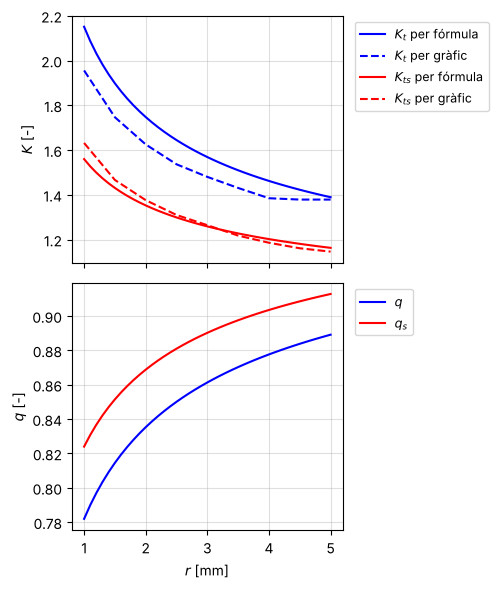

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(5.2, 6.0), sharex=True)
ax[0].plot(r_, R_['K_t'],  '-b',  linewidth=1.5, label='$K_t$ per fórmula')
ax[0].plot(r_, R_['K_tg'], '--b', linewidth=1.5, label='$K_t$ per gràfic')
ax[0].plot(r_, R_['K_ts'],  '-r',  linewidth=1.5, label='$K_{ts}$ per fórmula')
ax[0].plot(r_, R_['K_tsg'], '--r', linewidth=1.5, label='$K_{ts}$ per gràfic')
ax[0].set_ylabel('$K$ [-]'); ax[0].grid(True, alpha=0.4)
ax[0].legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=9)
ax[1].plot(r_, R_['q'],  '-b', linewidth=1.5, label='$q$')
ax[1].plot(r_, R_['qs'], '-r', linewidth=1.5, label='$q_s$')
ax[1].set_xlabel('$r$ [mm]'); ax[1].set_ylabel('$q$ [-]'); ax[1].grid(True, alpha=0.4)
ax[1].legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=9)
fig.tight_layout()
fig.savefig('DiAM_eixfix_K_Fig1.pdf', bbox_inches='tight')
fig.savefig('DiAM_eixfix_K_Fig1.svg', bbox_inches='tight')
plt.show()

### Tensió de von Mises

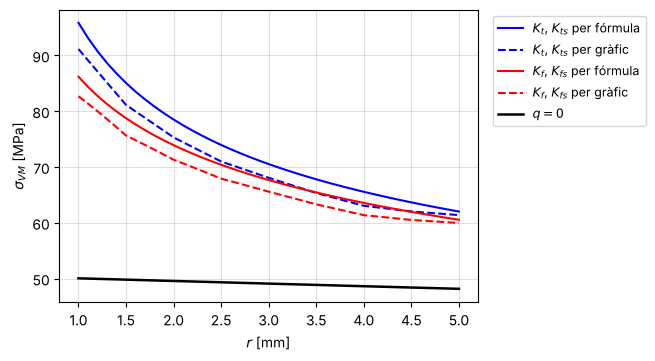

In [9]:
plt.figure(figsize=(5.4, 3.8))
plt.plot(r_, R_['VM_a'],  '-b',  linewidth=1.5, label='$K_t$, $K_{ts}$ per fórmula')
plt.plot(r_, R_['VM_ag'], '--b', linewidth=1.5, label='$K_t$, $K_{ts}$ per gràfic')
plt.plot(r_, R_['VM_b'],  '-r',  linewidth=1.5, label='$K_f$, $K_{fs}$ per fórmula')
plt.plot(r_, R_['VM_bg'], '--r', linewidth=1.5, label='$K_f$, $K_{fs}$ per gràfic')
plt.plot(r_, R_['VM_c'],  '-k',  linewidth=1.8, label='$q = 0$')
plt.xlabel('$r$ [mm]'); plt.ylabel('$\\sigma_{VM}$ [MPa]')
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=9)
plt.grid(True, alpha=0.4)
plt.savefig('DiAM_eixfix_VM_Fig2.pdf', bbox_inches='tight')
plt.savefig('DiAM_eixfix_VM_Fig2.svg', bbox_inches='tight')
plt.show()